In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
from tokenize import group

df = pd.read_csv('../chat_parsed.csv')
df_info = pd.read_csv('../group_info.csv')
group_name = df_info['group_name'].iloc[0]

print(group_name)

Drenas Espanholas


In [5]:
df.columns

Index(['timestamp', 'date', 'time', 'sender', 'message', 'media',
       'line_number', 'datetime', 'hour', 'day_of_week', 'month', 'year'],
      dtype='object')

In [6]:
#scrollab
df.head(20)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year
0,2021-09-03 22:42:08,03/09/21,22:42:08,Alexandre Reis,Malta temos de decidir pa onde é q vamos e com...,no,3,2021-09-03 22:42:08,22,Friday,September,2021
1,2021-09-04 06:04:12,04/09/21,06:04:12,Duarte Morais,Por mim espanha. Mas podemos ir a outro lado,no,4,2021-09-04 06:04:12,6,Saturday,September,2021
2,2021-09-04 12:16:23,04/09/21,12:16:23,Max Técnico,Eu tmb acho Espanha bacano,no,5,2021-09-04 12:16:23,12,Saturday,September,2021
3,2021-09-04 12:16:47,04/09/21,12:16:47,Max Técnico,Mas eu Espanha há imensa coisa,no,6,2021-09-04 12:16:47,12,Saturday,September,2021
4,2021-09-04 12:16:49,04/09/21,12:16:49,Max Técnico,Sevilha,no,7,2021-09-04 12:16:49,12,Saturday,September,2021
5,2021-09-04 12:16:56,04/09/21,12:16:56,Max Técnico,Barcelona valência,no,8,2021-09-04 12:16:56,12,Saturday,September,2021
6,2021-09-04 12:34:40,04/09/21,12:34:40,Kiks,Acho que Madrid tmb era bacano,no,9,2021-09-04 12:34:40,12,Saturday,September,2021
7,2021-09-04 12:35:18,04/09/21,12:35:18,Kiks,O meu irmão está lá a estagiar e diz me que es...,no,10,2021-09-04 12:35:18,12,Saturday,September,2021
8,2021-09-04 12:35:45,04/09/21,12:35:45,Kiks,Barcelona tive lá à pouco e está a fechar tudo...,no,11,2021-09-04 12:35:45,12,Saturday,September,2021
9,2021-09-04 14:45:13,04/09/21,14:45:13,Alexandre Reis,"Isso era bue chato, assim mais vale Madrid",no,12,2021-09-04 14:45:13,14,Saturday,September,2021


In [7]:
df['sender'].unique()

array(['Alexandre Reis', 'Duarte Morais', 'Max Técnico', 'Kiks',
       'Jay-B Tecnico', 'João Dias', 'Angelo', 'Francisco Vieira CPH'],
      dtype=object)

## 0. Feature Engineering

In [8]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['year'] = df['timestamp'].dt.year
df['hour'] = df['timestamp'].dt.hour
# ensure timestamp column is in datetime format
#coerce: Converts invalid values to NaT and continues
#raise: Raises an error for invalid values
#ignore: Ignores invalid values
df['day'] = df['timestamp'].dt.day_name()
df['accumulated_messages'] = df.groupby('sender')['message'].cumcount() + 1


In [9]:
df.head(5)

,timestamp,date,time,sender,message,media,line_number,datetime,hour,day_of_week,month,year,day,accumulated_messages
0,2021-09-03 22:42:08,03/09/21,22:42:08,Alexandre Reis,Malta temos de decidir pa onde é q vamos e com...,no,3,2021-09-03 22:42:08,22,Friday,September,2021,Friday,1
1,2021-09-04 06:04:12,04/09/21,06:04:12,Duarte Morais,Por mim espanha. Mas podemos ir a outro lado,no,4,2021-09-04 06:04:12,6,Saturday,September,2021,Saturday,1
2,2021-09-04 12:16:23,04/09/21,12:16:23,Max Técnico,Eu tmb acho Espanha bacano,no,5,2021-09-04 12:16:23,12,Saturday,September,2021,Saturday,1
3,2021-09-04 12:16:47,04/09/21,12:16:47,Max Técnico,Mas eu Espanha há imensa coisa,no,6,2021-09-04 12:16:47,12,Saturday,September,2021,Saturday,2
4,2021-09-04 12:16:49,04/09/21,12:16:49,Max Técnico,Sevilha,no,7,2021-09-04 12:16:49,12,Saturday,September,2021,Saturday,3


## 1.Temporal analysis

     hour          sender  message_count
0       0  Alexandre Reis            217
1       0   Duarte Morais            288
2       0   Jay-B Tecnico            161
3       0       João Dias            261
4       0            Kiks            128
..    ...             ...            ...
146    23   Duarte Morais            292
147    23   Jay-B Tecnico            239
148    23       João Dias            653
149    23            Kiks            192
150    23     Max Técnico            572

[151 rows x 3 columns]


Text(0, 0.5, 'Number of Messages')

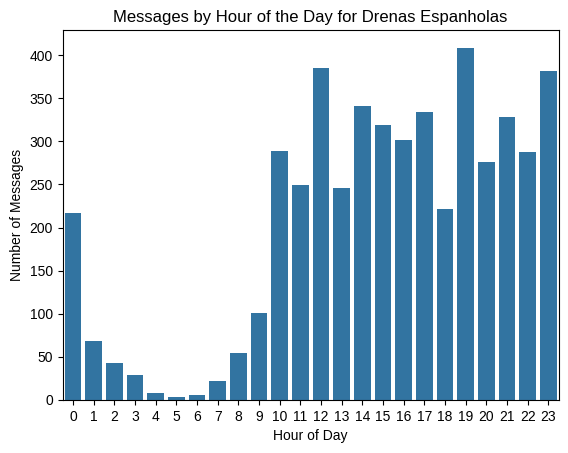

In [10]:
# plot message frequency by hour
#df['hour'].value_counts().sort_index().plot(kind='bar', color='steelblue')
hourly_counts = df.groupby(['hour', 'sender']).size().reset_index(name='message_count')
print(hourly_counts)
sns.barplot(data=hourly_counts, x='hour', y='message_count', errorbar=None)
plt.style.use('seaborn-v0_8')
plt.title(f'Messages by Hour of the Day for {group_name}')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Messages')


### Average activity during a week

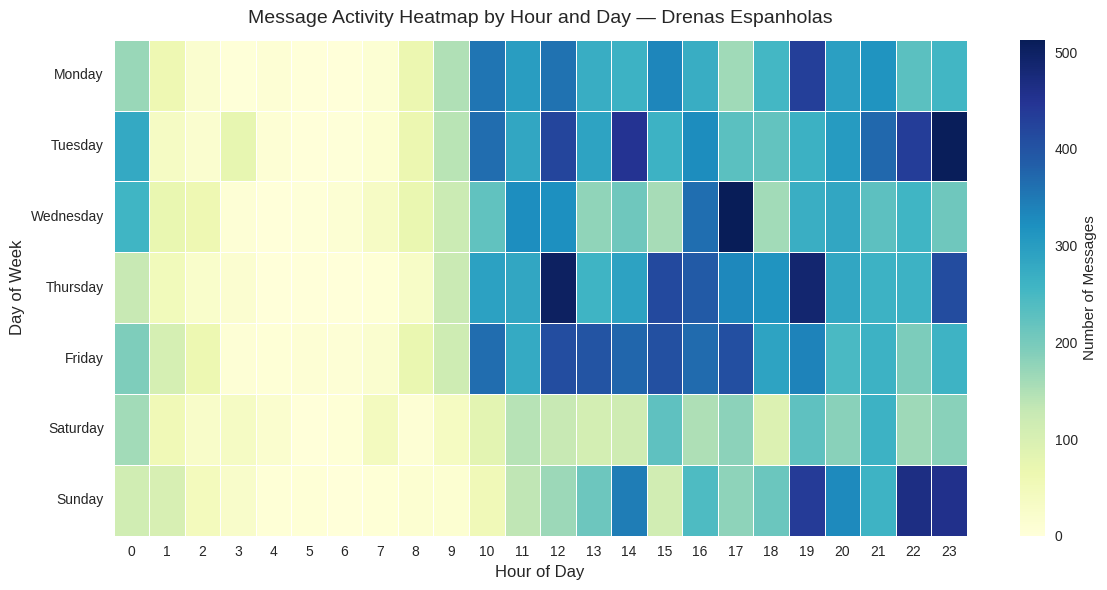

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# group by day and hour
heatmap_data = df.groupby(['day', 'hour']).size().unstack(fill_value=0)

# reorder days for better readability
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(days_order)

# plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', 
    linewidths=0.5, linecolor='white', 
    cbar_kws={'label': 'Number of Messages'}
)
plt.title(f'Message Activity Heatmap by Hour and Day — {group_name}', fontsize=14, pad=12)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Participation Analysis

### Typical content of message by user

/tmp/ipykernel_185346/3595932699.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')


           sender media  timestamp  message_count
0  Alexandre Reis    no 2021-09-30            290
1  Alexandre Reis    no 2021-10-31            173
2  Alexandre Reis    no 2021-11-30             54
3  Alexandre Reis    no 2021-12-31            187
4  Alexandre Reis    no 2022-01-31            110


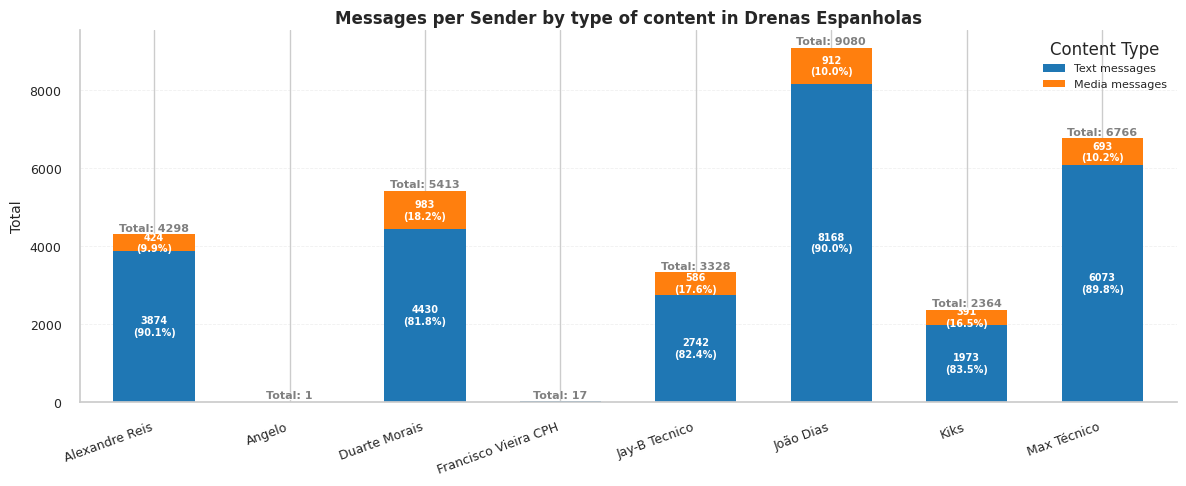

In [13]:
message_count = df.groupby(['sender', 'media', pd.Grouper(key='timestamp', freq='M')]).size().reset_index(name='message_count')
print(message_count.head())
pivot = (
    message_count
    .groupby(['sender', 'media'])['message_count']
    .sum()
    .unstack(fill_value=0)
)

# --- Compact plot style ---
sns.set_theme(style="whitegrid")
colors = ["#1f77b4", "#ff7f0e"]  # blue and orange

fig, ax = plt.subplots(figsize=(12, 5))
pivot.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors,
    width=0.6,
    edgecolor='none'
)

# --- Compact aesthetics ---
ax.set_title("Messages per Sender by type of content in {}".format(group_name), fontsize=12, fontweight="bold", pad=5)
ax.set_xlabel("")
ax.set_ylabel("Total", fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)
ax.tick_params(axis='y', labelsize=9)

# Minimal grid and borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.6)

# --- Annotate individual values and percentages ---
totals = pivot.sum(axis=1)
for i, (sender, row) in enumerate(pivot.iterrows()):
    total = row.sum()
    
    # Calculate percentages
    no_pct = (row.get('no', 0) / total * 100) if total > 0 else 0
    yes_pct = (row.get('yes', 0) / total * 100) if total > 0 else 0
    
    # Get individual values
    no_count = row.get('no', 0)
    yes_count = row.get('yes', 0)
    
    # Annotate "no" (regular messages) - bottom of stack
    if no_count > 0:
        ax.text(i, no_count/2, f"{int(no_count)}\n({no_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate "yes" (media messages) - top of stack
    if yes_count > 0:
        ax.text(i, no_count + yes_count/2, f"{int(yes_count)}\n({yes_pct:.1f}%)", 
                ha='center', va='center', fontsize=7, color='white', fontweight='bold')
    
    # Annotate total at the top
    ax.text(i, total + 30, f"Total: {int(total)}", ha='center', va='bottom', 
            fontsize=8, color='gray', fontweight='bold')

# --- Legend ---
ax.legend(title="Content Type", fontsize=8, loc='upper right', frameon=False)

# Update legend labels
legend = ax.get_legend()
if legend:
    legend.get_texts()[0].set_text('Text messages')  # Changes 'no' to 'Text messages'
    legend.get_texts()[1].set_text('Media messages')  # Changes 'yes' to 'Media messages'


plt.tight_layout(pad=1)
plt.show()



### Boxplots (Top view of dist.)

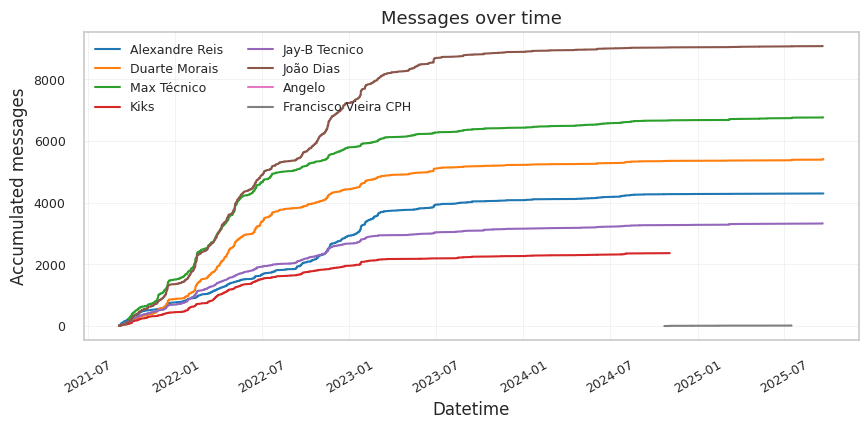

In [14]:
sns.set_palette("tab10")  # or try "tab10", "colorblind", "Dark2"
fig, ax = plt.subplots(figsize=(10, 4))
df['timestamp_'] = pd.to_datetime(df['timestamp'][1:])
sns.lineplot(data=df, x="timestamp_", y="accumulated_messages", hue="sender")
plt.title("Messages over time", fontsize=13)
plt.xlabel("Datetime")
plt.ylabel("Accumulated messages")
# Compact tick formatting
plt.xticks(rotation=30, fontsize=9)
plt.yticks(fontsize=9)
plt.grid(True, alpha=0.3, linewidth=0.6)
#more space between the lines
# Compact legend
plt.legend(
    title=None,
    fontsize=9,
    loc="upper left",
    frameon=False,
    ncol=2  # 2-column legend to save space
)
plt.show()

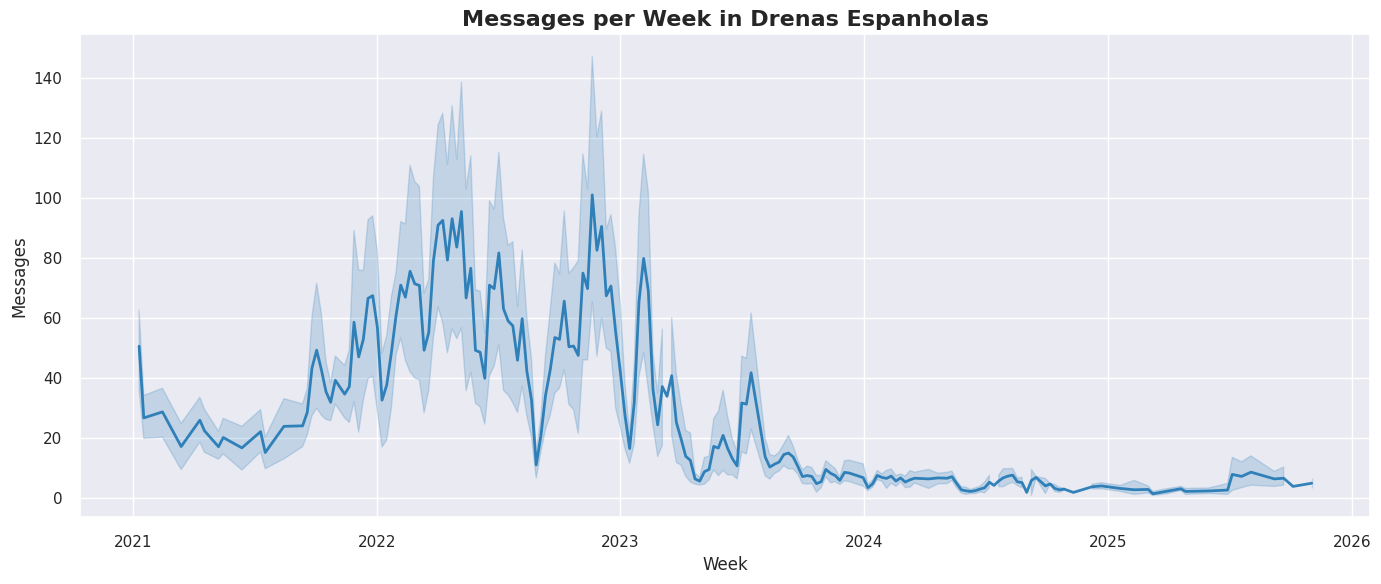

          sender       date  messages_per_week  messages_smooth
569    João Dias 2022-11-20                315       198.666667
830  Max Técnico 2021-12-19                247       106.666667
541    João Dias 2022-05-08                244       166.333333
579    João Dias 2023-01-29                227       122.666667
530    João Dias 2022-02-20                226       146.666667


In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure 'date' is a datetime
df['date'] = pd.to_datetime(df['date'])
#df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

# --- Aggregate per sender per week ---
weekly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='W')])
    .size()
    .reset_index(name='messages_per_week')
)

# --- 3-week moving average for smoother trends ---
weekly_counts['messages_smooth'] = (
    weekly_counts.groupby('sender')['messages_per_week']
    .transform(lambda x: x.rolling(3, min_periods=1).mean())
)

# --- Plot ---
plt.style.use("dark_background")
sns.set_theme(style="darkgrid", palette="tab10")

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=weekly_counts,
    x="date",
    y="messages_smooth",
    linewidth=2.0,
    alpha=0.9
)

plt.title(f"Messages per Week in {group_name}", fontsize=16, fontweight='bold')
plt.xlabel("Week")
plt.ylabel("Messages")
plt.tight_layout()
plt.show()

# --- Optional: top 5 busiest weeks ---
print(
    weekly_counts.sort_values(by='messages_per_week', ascending=False)
    .head(5)
)


In [18]:
#i want to find the top five senders with the most messages in one day which I dont know the date
#so I need to find the top five senders with the most messages in one day
#I can do this by grouping by sender and date and then counting the number of messages
#and then sorting by the number of messages
#and then getting the top five
df.groupby(['sender', 'date']).size().sort_values(ascending=False).head(5)


sender       date      
João Dias    2023-01-24    135
             2022-05-05    127
             2022-11-02    108
Max Técnico  2022-05-05    104
João Dias    2022-02-15    104
dtype: int64

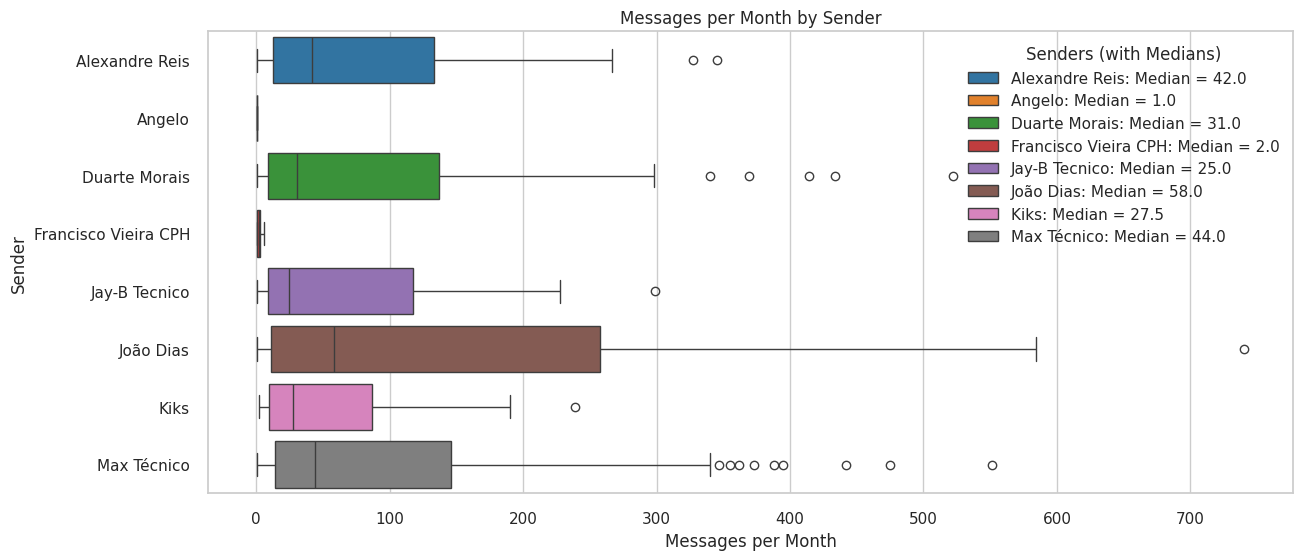

In [19]:
# Ensure 'date' is datetime
df['date'] = pd.to_datetime(df['date'])

# --- Aggregate per sender per month ---
monthly_counts = (
    df.groupby(['sender', pd.Grouper(key='date', freq='ME')])
    .size()
    .reset_index(name='messages_per_month')
)
# --- Plot grouped bar chart ---
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid", palette="tab10")
# Calculate medians for each sender
medians = monthly_counts.groupby('sender')['messages_per_month'].median()
# Create legend with median values


sns.boxplot(data=monthly_counts,
    x="messages_per_month",
    y="sender",
    hue="sender"
)

legend_labels = [f"{sender}: Median = {median:.1f}" for sender, median in medians.items()]
plt.legend(legend_labels, title="Senders (with Medians)", loc='upper right', bbox_to_anchor=(1.0, 1.0))
plt.title("Messages per Month by Sender")
plt.xlabel("Messages per Month")
plt.ylabel("Sender")
plt.show()

### Barplot

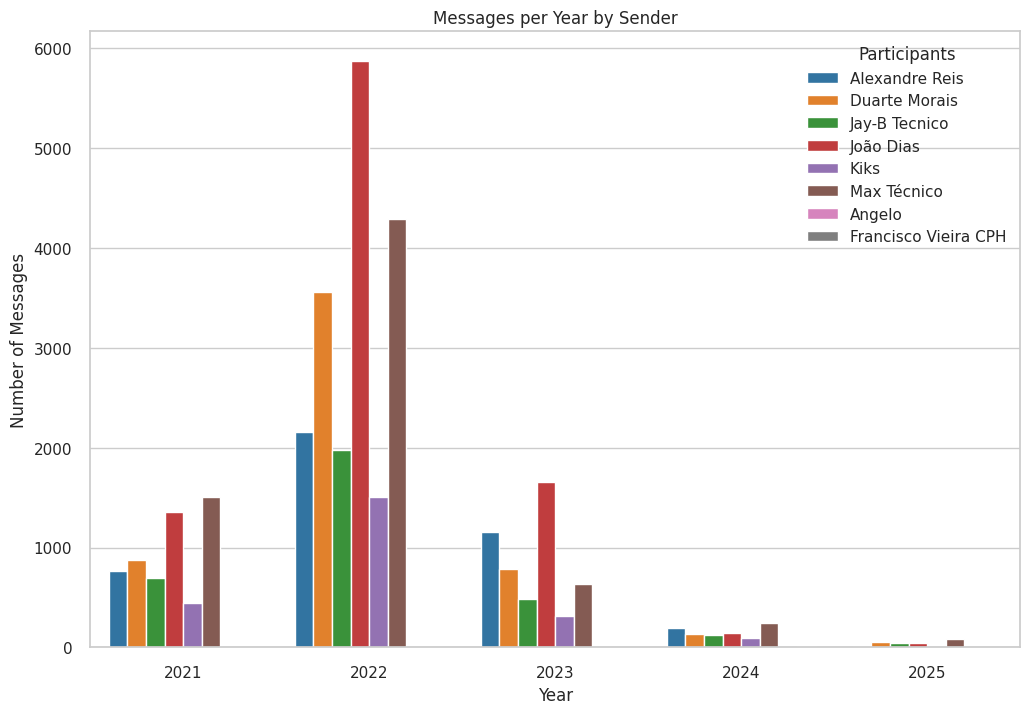

In [20]:
# Create yearly message counts
yearly_messages = df.groupby(['year', 'sender']).size().reset_index(name='message_count')

# Stacked bar chart by year
plt.figure(figsize=(12, 8))
sns.barplot(data=yearly_messages, x='year', y='message_count', hue='sender')
plt.title('Messages per Year by Sender')
plt.xlabel('Year')
plt.ylabel('Number of Messages')
plt.legend(title='Participants')
plt.show()

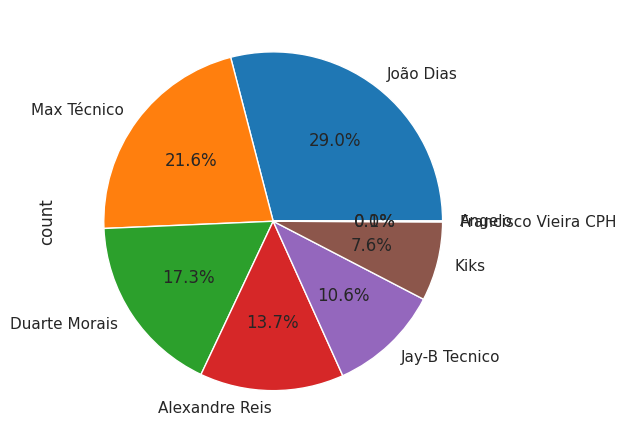

In [21]:
#seaborn pie chart
df['sender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.show()


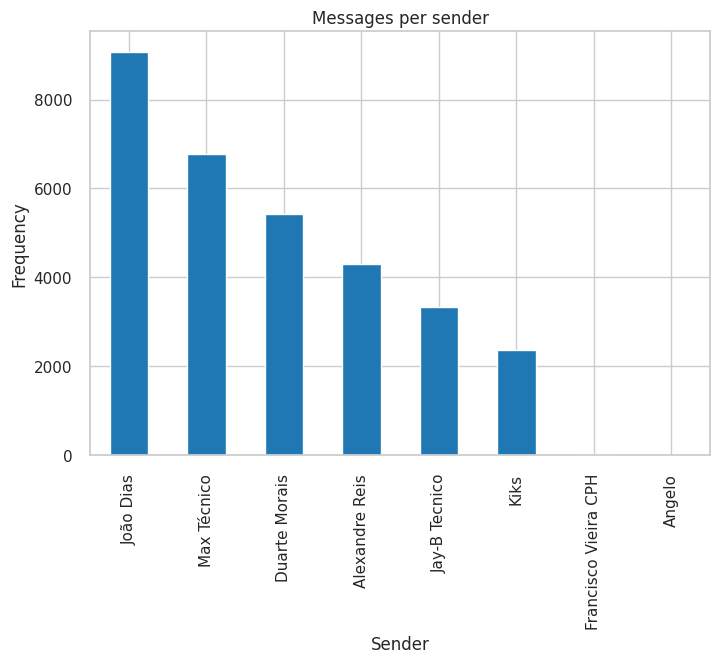

sender
João Dias               29.04
Max Técnico             21.64
Duarte Morais           17.31
Alexandre Reis          13.75
Jay-B Tecnico           10.64
Kiks                     7.56
Francisco Vieira CPH     0.05
Angelo                   0.00
Name: proportion, dtype: float64

In [22]:
#percentage of messages per sender
df['sender'].value_counts(normalize=True)

#total messages per sender
df['sender'].value_counts()

#in a bar plot
ax = df['sender'].value_counts().plot(kind='bar') 
ax.set_title('Messages per sender')
ax.set_xlabel('Sender')
ax.set_ylabel('Frequency')
plt.show()

(df['sender'].value_counts(normalize=True) * 100).round(2)


# Sentiment Analysis

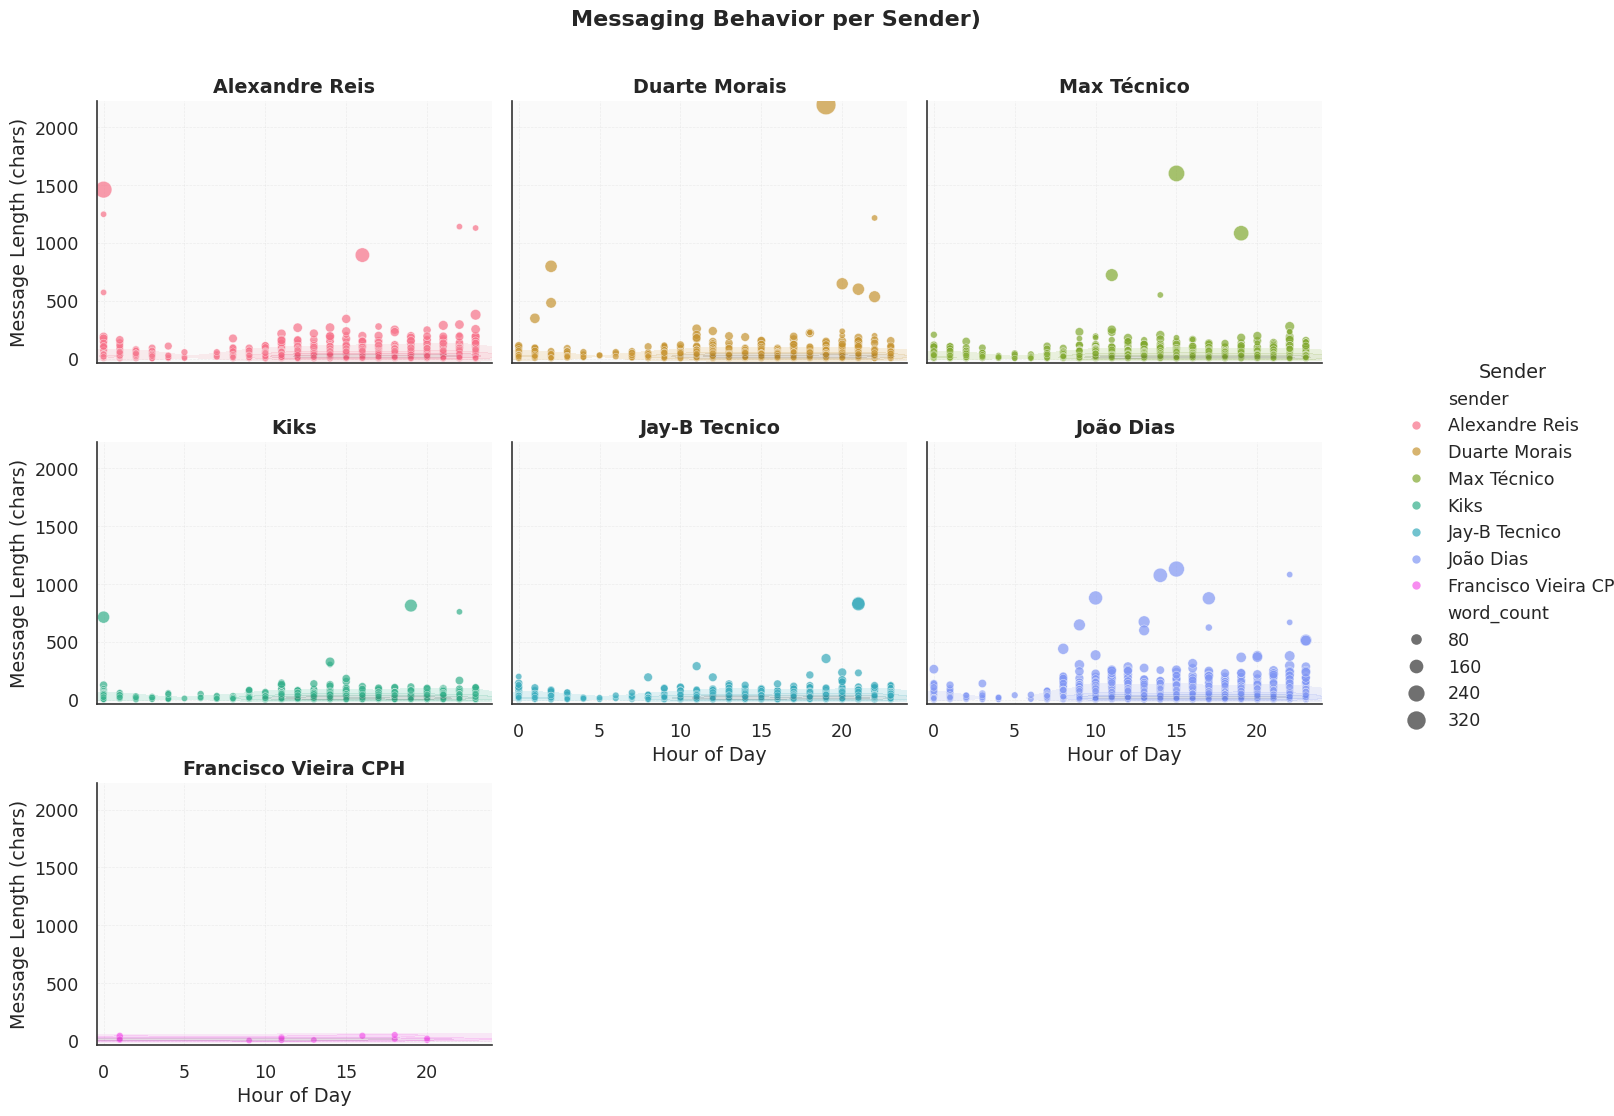

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ensure datetime and hour columns are correct
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['date'] = df['timestamp'].dt.date

# Filter out media messages
df_text = df[df['media'] == 'no'].copy()

# ✅ Only include senders with more than 5 messages
sender_counts = df_text['sender'].value_counts()
valid_senders = sender_counts[sender_counts > 5].index
df_filtered = df_text[df_text['sender'].isin(valid_senders)]

# Define color palette by sender
senders = df_filtered['sender'].unique()
palette = sns.color_palette("husl", len(senders))

sns.set_theme(style="whitegrid", font_scale=1.15, rc={
    "axes.edgecolor": "0.2",
    "axes.linewidth": 1.2,
    "grid.alpha": 0.2
})

# Main plot using relplot (auto-handles facets & legends)
g = sns.relplot(
    data=df_filtered,
    x="hour",
    y="message_length",
    hue="sender",
    size="word_count",
    sizes=(20, 200),
    alpha=0.70,
    palette=palette,
    col="sender",
    col_wrap=3,
    kind="scatter",
    height=3.8,
    aspect=1.2,
)

# KDE contours for each sender (for density visualization)
for ax, sender in zip(g.axes.flatten(), senders):
    sns.kdeplot(
        data=df_filtered[df_filtered['sender'] == sender],
        x="hour",
        y="message_length",
        fill=True,
        alpha=0.18,
        levels=5,
        ax=ax,
        color=palette[list(senders).index(sender)]
    )

# Improve readability
g.set_titles("{col_name}", fontweight="bold", fontsize=11)
g.set_axis_labels("Hour of Day", "Message Length (chars)")
g.set(xlim=(-0.4, 24))
for ax in g.axes.flatten():
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.set_facecolor("#fafafa")

# Global title
plt.subplots_adjust(top=0.9, hspace=0.3)
g.fig.suptitle("Messaging Behavior per Sender)", 
               fontsize=16, weight="bold")

# Adjust legend position and title
g._legend.set_bbox_to_anchor((1.02, 0.5))
g._legend.set_title("Sender")

plt.show()


In [24]:
#average menssage lenght
df['message_length'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['average_word_length'] = df['message_length'] / df['word_count']
df.groupby('sender')[['message_length', 'word_count', 'average_word_length']].mean()

,message_length,word_count,average_word_length
sender,,,
Alexandre Reis,36.402280,6.505584,7.880099
Angelo,39.000000,8.000000,4.875000
Duarte Morais,32.848143,5.356919,8.635947
Francisco Vieira CPH,22.294118,3.529412,7.253221
Jay-B Tecnico,30.590445,4.755409,8.602161
João Dias,39.260463,7.227974,7.003532
Kiks,29.706007,4.591794,8.811844
Max Técnico,26.930092,4.803725,7.188399


   gap_flag  gap_minutes           timestamp
0        no          NaN 2021-09-03 22:42:08
1        no   442.066667 2021-09-04 06:04:12
2        no   372.183333 2021-09-04 12:16:23
3       yes     0.400000 2021-09-04 12:16:47
4       yes     0.033333 2021-09-04 12:16:49
5       yes     0.116667 2021-09-04 12:16:56
6        no    17.733333 2021-09-04 12:34:40
7       yes     0.633333 2021-09-04 12:35:18
8       yes     0.450000 2021-09-04 12:35:45
9        no   129.466667 2021-09-04 14:45:13
10       no   127.716667 2021-09-04 16:52:56
11       no     6.800000 2021-09-04 16:59:44
12       no   144.616667 2021-09-04 19:24:21
13      yes     0.600000 2021-09-04 19:24:57
14      yes     0.366667 2021-09-04 19:25:19
15      yes     0.683333 2021-09-04 19:26:00
16      yes     0.183333 2021-09-04 19:26:11
17      yes     0.550000 2021-09-04 19:26:44
18      yes     0.050000 2021-09-04 19:26:47
19      yes     0.233333 2021-09-04 19:27:01


<Axes: xlabel='year', ylabel='gap_minutes'>

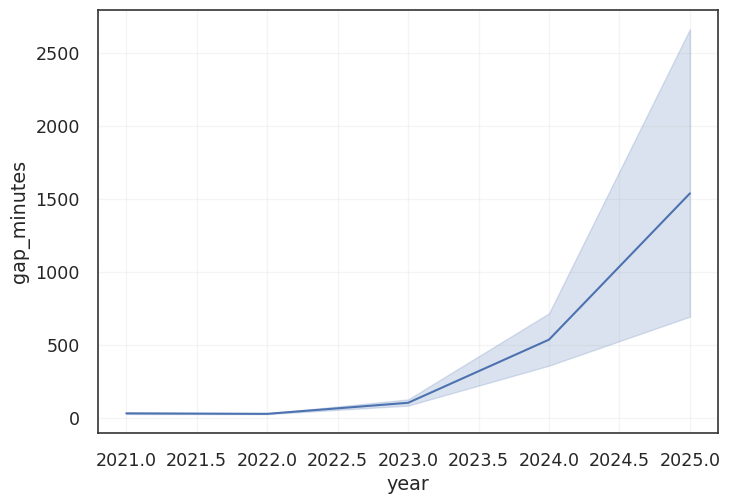

In [26]:
df['time_gap'] = df['timestamp'].diff()
df['gap_seconds'] = df['time_gap'].dt.total_seconds()
df['gap_minutes'] = df['gap_seconds'] / 60

#I want to mark as yes if the gap is less than 5 minutes for N messages in a row
#and have to be more than 10 messages in a row to all get the flag as yes
df['gap_flag'] = df['gap_minutes'].apply(lambda x: 'yes' if x < 2 else 'no')

# Remove first row (NaN) and filter out negative gaps (data issues)
gaps = df['gap_seconds'].dropna()
gaps = gaps[gaps >= 0]  # Remove any negative gaps

print(df[["gap_flag", "gap_minutes", "timestamp"]][0:20])

sns.lineplot(data=df, x="year", y="gap_minutes")


/home/duarte33/Documents/agora/venv2/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128077 (\N{THUMBS UP SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/duarte33/Documents/agora/venv2/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129392 (\N{SMILING FACE WITH SMILING EYES AND THREE HEARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


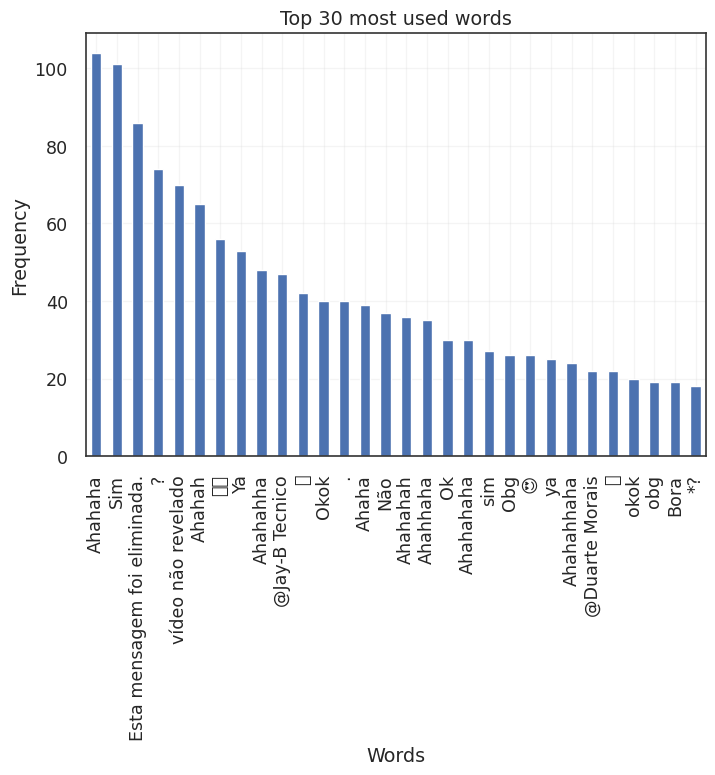

In [27]:
#top most used words
#top most used words
ax = df['message'].value_counts().head(30).plot(kind='bar')
ax.set_title('Top 30 most used words')
ax.set_xlabel('Words')
ax.set_ylabel('Frequency')
plt.show()


In [28]:
import nltk
nltk.download('stopwords')  # Download stopwords data first
from nltk.corpus import stopwords
stopwords = set(stopwords.words('portuguese'))
stopwords.update(['imagem', 'video', 'revelada', 'não', 'Não', 'revelado'])
import re
from collections import Counter

# Get all words
all_words = re.findall(r'\b\w+\b', ' '.join(df['message'].astype(str)).lower())

# Words with only 2 different letters
def has_only_two_unique_letters(word):
    """Check if a word has only 2 unique letters."""
    unique_letters = set(word.lower())
    return len(unique_letters) == 2


# Filter words with only 2 unique letters
for word in all_words:
    word = word.lower()
two_letter_words = [word for word in all_words if has_only_two_unique_letters(word) and len(word) > 2]
print("Words with only 2 different letters:", Counter(two_letter_words).most_common(10))

stopwords.update(two_letter_words)

# Split all sender names and add individual words
all_sender_words = ' '.join(df['sender'].unique()).split()
stopwords.update(all_sender_words)

#except the last one
senders = df['sender'].unique()[1:]
for sender in senders:
    sender_messages = df[df['sender'] == sender]
    all_words = ' '.join(sender_messages['message']).split()
    
    # Calculate word frequencies
    word_freq = {}
    for word in all_words:
        word_freq[word] = word_freq.get(word, 0) + 1
    
    # Sort words by frequency in descending order
    sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
    #filter out words with less than 2 letters
    sorted_words = [word for word in sorted_words if len(word[0]) >= 4]
    #filter out words that are in the stopwords list
    sorted_words = [word for word in sorted_words if word[0] not in stopwords]

    # Get top 5 most distinctive words
    top_words = sorted_words[:5]
    
    # Print results
    print(f"Top 5 most distinctive words for {sender}:")

    # Print top 5 words with their frequencies
    for word, freq in top_words:
        print(f"{word}: {freq}")
    print("\n")



ModuleNotFoundError: No module named 'nltk'